In [ ]:
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf,ccf

df = pd.read_csv("/content/drive/MyDrive/Fatma/DATA SIAP PAKAI/all_data_transformed.csv")

df = df.sort_values('Tanggal')
print(df.head())
folder = "/content/drive/MyDrive/Fatma/DATA SIAP PAKAI/Grafik_ACF_CCF/"

Mounted at /content/drive
   Tanggal  BI_Rate  Inflasi    kurs  Minyak_Mentah  Tingkat_Pengangguran  \
0  2010-01      6.5     0.84  9275.0          76.17                  7.49   
1  2010-02      6.5    -0.08  9348.0          73.75                  7.41   
2  2010-03      6.5    -0.14  9174.0          78.83                  7.36   
3  2010-04      6.5     0.15  9027.0          84.82                  7.32   
4  2010-05      6.5     0.29  9183.0          75.95                  7.28   

   Nilai_Uang_Beredar         IHSG  
0         206648099.0  2575.312988  
1          21120827.0  2587.448242  
2         211602354.0  2554.574463  
3         214323405.0  2829.885986  
4         223114433.0  2960.779785  


# ACF Inflasi

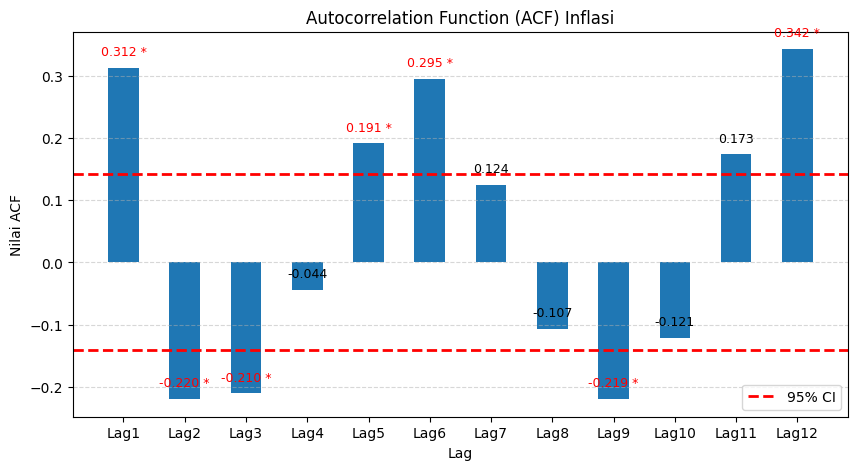

In [ ]:
#Autocorrelation Function (ACF) untuk Inflasi

acf_values, confint = acf(
    df["Inflasi"],
    nlags=12,
    alpha=0.05
)


#Menampilkan Tabel Hasi ACF
hasil_acf = pd.DataFrame({
    'Lag': range(len(acf_values)),
    'ACF': acf_values,
    "Lower CI": confint[:,0],
    "Upper CI": confint[:,1]
})
hasil_acf["Signifikan"] = (
    (hasil_acf["Lower CI"] > 0) |
    (hasil_acf["Upper CI"] < 0)
)

#Hilangkan Lag 0
hasil_acf = hasil_acf[hasil_acf["Lag"] != 0]
# print(hasil_acf)

plt.figure(figsize=(10,5))

plt.bar(
    hasil_acf["Lag"],
    hasil_acf["ACF"],
    width=0.5
)

# Confidence Interval (95%)
ci = 1.96 / np.sqrt(len(df))

plt.axhline(ci,
            color='red',
            linestyle='--',
            linewidth=2,
            label='95% CI')

plt.axhline(-ci,
            color='red',
            linestyle='--',
            linewidth=2)

# Menampilkan nilai di atas batang
for _, row in hasil_acf.iterrows():

    label = f'{row["ACF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["ACF"] + 0.02,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.xticks(
    hasil_acf["Lag"],
    [f"Lag{i}" for i in hasil_acf["Lag"]]
)

plt.xlabel("Lag")
plt.ylabel("Nilai ACF")
plt.title("Autocorrelation Function (ACF) Inflasi")

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_ACF_Inflasi.jpeg",
    dpi=600,
    bbox_inches='tight'
)

plt.show()

# CCF Bi Rate

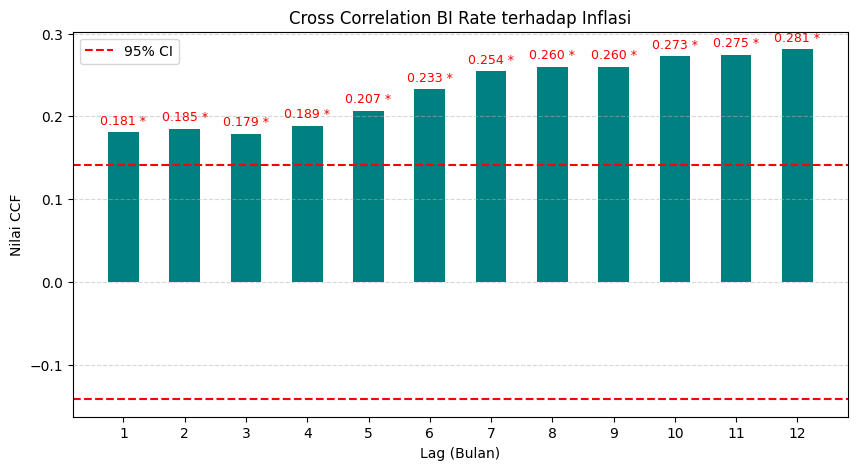

In [ ]:
#Cross Correlation Bi Rate Vs Inflasi
corr = ccf(
    df['BI_Rate'],
    df['Inflasi']
)
# Batasi sampai lag 12
corr = corr[:13]

# Jumlah observasi
N = len(df)

# Confidence Interval 95%
ci = 1.96 / np.sqrt(N)

# Membuat tabel hasil CCF
hasil_ccf = pd.DataFrame({
    'Lag': range(len(corr)),
    'CCF': corr,
    'Lower CI': -ci,
    'Upper CI': ci
})

# Menentukan apakah lag signifikan
hasil_ccf["Signifikan"] = (
    (hasil_ccf["CCF"] < hasil_ccf["Lower CI"]) |
    (hasil_ccf["CCF"] > hasil_ccf["Upper CI"])
)

# print(hasil_ccf)

#Hilangkan Lag 0
hasil_ccf = hasil_ccf[hasil_ccf["Lag"] != 0]
# print(hasil_ccf)

# Membuat diagram batang
plt.figure(figsize=(10,5))

plt.bar(
    hasil_ccf["Lag"],
    hasil_ccf["CCF"],
    width=0.5,
    color="teal"
)

for _, row in hasil_ccf.iterrows():

    label = f'{row["CCF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["CCF"] + 0.01,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.axhline(ci, color='red', linestyle='--', label='95% CI')
plt.axhline(-ci, color='red', linestyle='--')

plt.xticks(hasil_ccf["Lag"])
plt.xlabel("Lag (Bulan)")
plt.ylabel("Nilai CCF")
plt.title("Cross Correlation BI Rate terhadap Inflasi")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_CCF_Bi_Rate_vs_Inflasi.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# CCF KURS

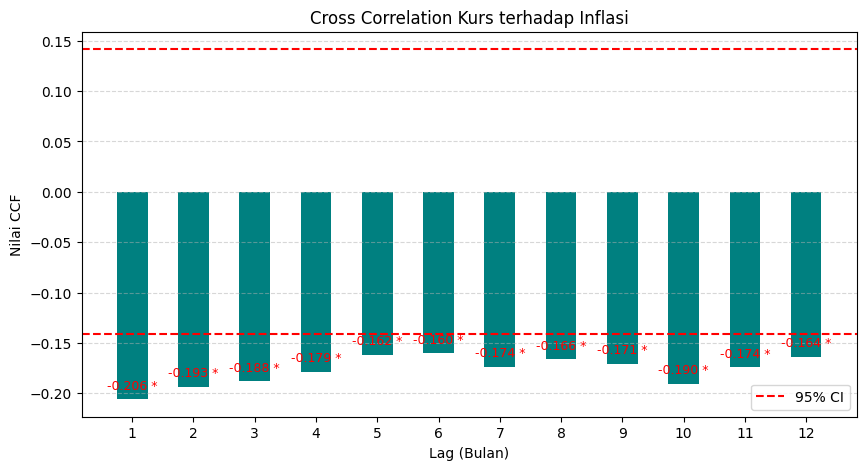

In [ ]:
#Cross Correlation Kurs Vs Inflasi
# Hitung CCF
corr = ccf(df['kurs'], df['Inflasi'])

# Batasi sampai lag 12
corr = corr[:13]

# Jumlah observasi
N = len(df)

# Confidence Interval 95%
ci = 1.96 / np.sqrt(N)

# Membuat tabel hasil CCF
hasil_ccf = pd.DataFrame({
    'Lag': range(len(corr)),
    'CCF': corr,
    'Lower CI': -ci,
    'Upper CI': ci
})

# Menentukan apakah lag signifikan
hasil_ccf["Signifikan"] = (
    (hasil_ccf["CCF"] < hasil_ccf["Lower CI"]) |
    (hasil_ccf["CCF"] > hasil_ccf["Upper CI"])
)

# print(hasil_ccf)

#Hilangkan Lag 0
hasil_ccf = hasil_ccf[hasil_ccf["Lag"] != 0]
# print(hasil_ccf)


# Membuat diagram batang
plt.figure(figsize=(10,5))

plt.bar(
    hasil_ccf["Lag"],
    hasil_ccf["CCF"],
    width=0.5,
    color="teal"
)

for _, row in hasil_ccf.iterrows():

    label = f'{row["CCF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["CCF"] + 0.01,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.axhline(ci, color='red', linestyle='--', label='95% CI')
plt.axhline(-ci, color='red', linestyle='--')

plt.xticks(hasil_ccf["Lag"])
plt.xlabel("Lag (Bulan)")
plt.ylabel("Nilai CCF")
plt.title("Cross Correlation Kurs terhadap Inflasi")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_CCF_Kurs_vs_Inflasi.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# CCF IHSG

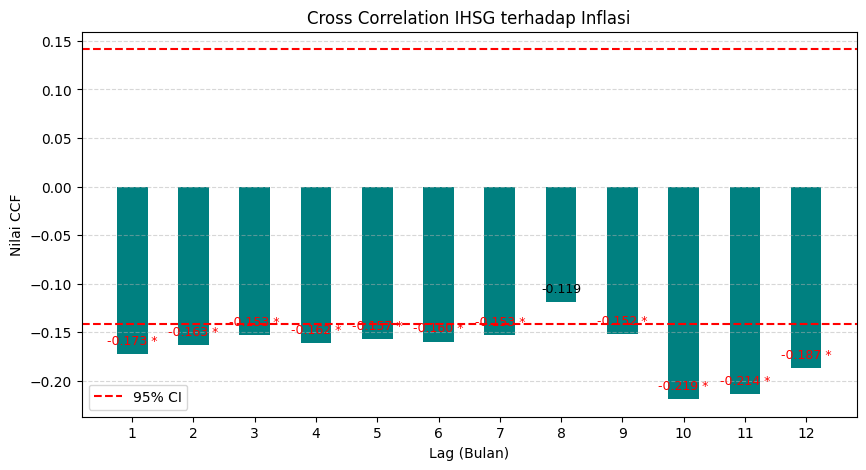

In [ ]:
#Cross Correlation IHSG Vs Inflasi
# Hitung CCF
corr = ccf(df['IHSG'], df['Inflasi'])

# Batasi sampai lag 12
corr = corr[:13]

# Jumlah observasi
N = len(df)

# Confidence Interval 95%
ci = 1.96 / np.sqrt(N)

# Membuat tabel hasil CCF
hasil_ccf = pd.DataFrame({
    'Lag': range(len(corr)),
    'CCF': corr,
    'Lower CI': -ci,
    'Upper CI': ci
})

# Menentukan apakah lag signifikan
hasil_ccf["Signifikan"] = (
    (hasil_ccf["CCF"] < hasil_ccf["Lower CI"]) |
    (hasil_ccf["CCF"] > hasil_ccf["Upper CI"])
)


#Hilangkan Lag 0
hasil_ccf = hasil_ccf[hasil_ccf["Lag"] != 0]
# print(hasil_ccf)


# Membuat diagram batang
plt.figure(figsize=(10,5))

plt.bar(
    hasil_ccf["Lag"],
    hasil_ccf["CCF"],
    width=0.5,
    color="teal"
)

for _, row in hasil_ccf.iterrows():

    label = f'{row["CCF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["CCF"] + 0.01,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.axhline(ci, color='red', linestyle='--', label='95% CI')
plt.axhline(-ci, color='red', linestyle='--')

plt.xticks(hasil_ccf["Lag"])
plt.xlabel("Lag (Bulan)")
plt.ylabel("Nilai CCF")
plt.title("Cross Correlation IHSG terhadap Inflasi")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_CCF_IHSG_vs_Inflasi.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# CCF Nilai Uang Beredar

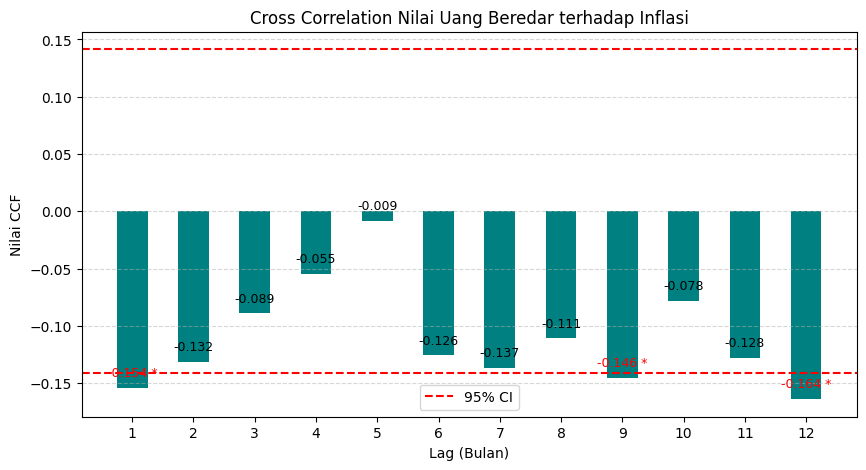

In [ ]:
#Cross Correlation Nilai Uang Beredar Vs Inflasi
# Hitung CCF
corr = ccf(df['Nilai_Uang_Beredar'], df['Inflasi'])

# Batasi sampai lag 12
corr = corr[:13]

# Jumlah observasi
N = len(df)

# Confidence Interval 95%
ci = 1.96 / np.sqrt(N)

# Membuat tabel hasil CCF
hasil_ccf = pd.DataFrame({
    'Lag': range(len(corr)),
    'CCF': corr,
    'Lower CI': -ci,
    'Upper CI': ci
})

# Menentukan apakah lag signifikan
hasil_ccf["Signifikan"] = (
    (hasil_ccf["CCF"] < hasil_ccf["Lower CI"]) |
    (hasil_ccf["CCF"] > hasil_ccf["Upper CI"])
)


#Hilangkan Lag 0
hasil_ccf = hasil_ccf[hasil_ccf["Lag"] != 0]
# print(hasil_ccf)


# Membuat diagram batang
plt.figure(figsize=(10,5))

plt.bar(
    hasil_ccf["Lag"],
    hasil_ccf["CCF"],
    width=0.5,
    color="teal"
)

for _, row in hasil_ccf.iterrows():

    label = f'{row["CCF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["CCF"] + 0.01,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.axhline(ci, color='red', linestyle='--', label='95% CI')
plt.axhline(-ci, color='red', linestyle='--')

plt.xticks(hasil_ccf["Lag"])
plt.xlabel("Lag (Bulan)")
plt.ylabel("Nilai CCF")
plt.title("Cross Correlation Nilai Uang Beredar terhadap Inflasi")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_CCF_Nilai_Uang_Beredar_vs_Inflasi.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# CCF Minyak Mentah

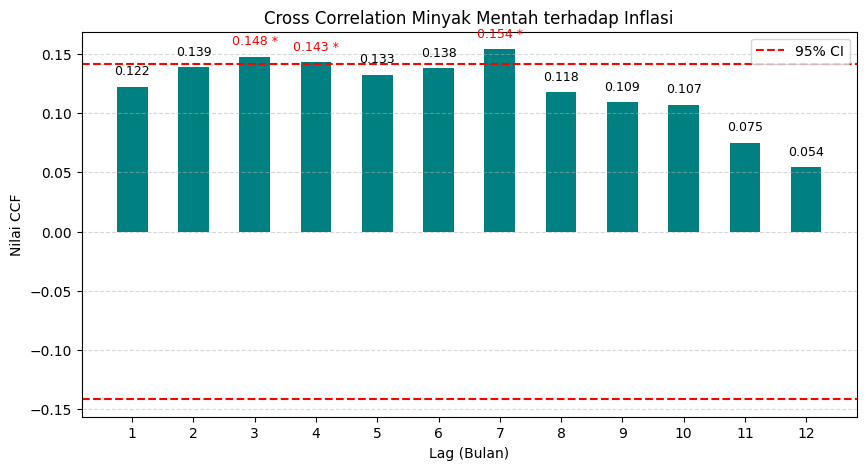

In [ ]:
#Cross Correlation Minyak Mentah Vs Inflasi
# Hitung CCF
corr = ccf(df['Minyak_Mentah'], df['Inflasi'])

# Batasi sampai lag 12
corr = corr[:13]

# Jumlah observasi
N = len(df)

# Confidence Interval 95%
ci = 1.96 / np.sqrt(N)

# Membuat tabel hasil CCF
hasil_ccf = pd.DataFrame({
    'Lag': range(len(corr)),
    'CCF': corr,
    'Lower CI': -ci,
    'Upper CI': ci
})

# Menentukan apakah lag signifikan
hasil_ccf["Signifikan"] = (
    (hasil_ccf["CCF"] < hasil_ccf["Lower CI"]) |
    (hasil_ccf["CCF"] > hasil_ccf["Upper CI"])
)


#Hilangkan Lag 0
hasil_ccf = hasil_ccf[hasil_ccf["Lag"] != 0]
# print(hasil_ccf)

# Membuat diagram batang
plt.figure(figsize=(10,5))

plt.bar(
    hasil_ccf["Lag"],
    hasil_ccf["CCF"],
    width=0.5,
    color="teal"
)

for _, row in hasil_ccf.iterrows():

    label = f'{row["CCF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["CCF"] + 0.01,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.axhline(ci, color='red', linestyle='--', label='95% CI')
plt.axhline(-ci, color='red', linestyle='--')

plt.xticks(hasil_ccf["Lag"])
plt.xlabel("Lag (Bulan)")
plt.ylabel("Nilai CCF")
plt.title("Cross Correlation Minyak Mentah terhadap Inflasi")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_CCF_Minyak_Mentah_vs_Inflasi.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# CCF Pengangguran

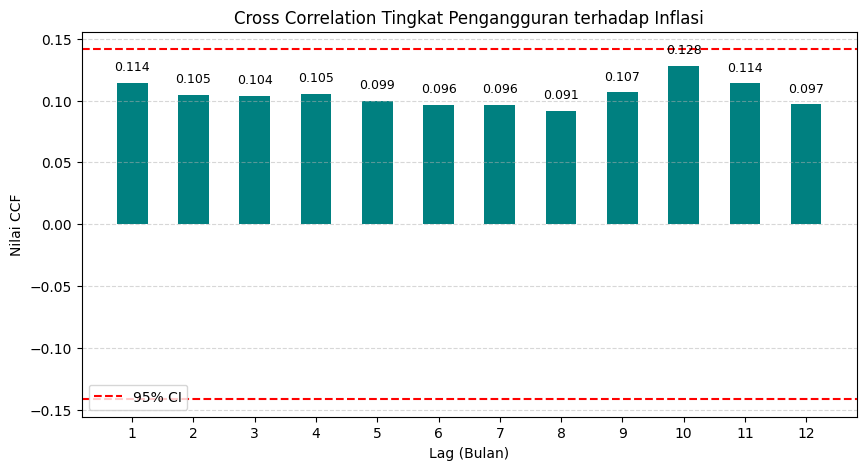

In [ ]:
#Cross Correlation Tingkat Pengangguran Vs Inflasi
# Hitung CCF
corr = ccf(df['Tingkat_Pengangguran'], df['Inflasi'])

# Batasi sampai lag 12
corr = corr[:13]

# Jumlah observasi
N = len(df)

# Confidence Interval 95%
ci = 1.96 / np.sqrt(N)

# Membuat tabel hasil CCF
hasil_ccf = pd.DataFrame({
    'Lag': range(len(corr)),
    'CCF': corr,
    'Lower CI': -ci,
    'Upper CI': ci
})

# Menentukan apakah lag signifikan
hasil_ccf["Signifikan"] = (
    (hasil_ccf["CCF"] < hasil_ccf["Lower CI"]) |
    (hasil_ccf["CCF"] > hasil_ccf["Upper CI"])
)


#Hilangkan Lag 0
hasil_ccf = hasil_ccf[hasil_ccf["Lag"] != 0]
# print(hasil_ccf)

# Membuat diagram batang
plt.figure(figsize=(10,5))

plt.bar(
    hasil_ccf["Lag"],
    hasil_ccf["CCF"],
    width=0.5,
    color="teal"
)

for _, row in hasil_ccf.iterrows():

    label = f'{row["CCF"]:.3f}'

    if row["Signifikan"]:
        label += " *"

    plt.text(
        row["Lag"],
        row["CCF"] + 0.01,
        label,
        ha='center',
        fontsize=9,
        color='red' if row["Signifikan"] else 'black'
    )

plt.axhline(ci, color='red', linestyle='--', label='95% CI')
plt.axhline(-ci, color='red', linestyle='--')

plt.xticks(hasil_ccf["Lag"])
plt.xlabel("Lag (Bulan)")
plt.ylabel("Nilai CCF")
plt.title("Cross Correlation Tingkat Pengangguran terhadap Inflasi")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend()

plt.savefig(
    folder + "Grafik_CCF_Tingkat_Pengangguran_vs_Inflasi.jpeg",
    dpi=600,
    bbox_inches="tight"
)

plt.show()